# Twizzle: X3D-S (Kinetics-pretrained) (Person 2)

Trains, tunes and exports **X3D-S (Kinetics-pretrained)** for the 11-class element classifier. Everything heavy lives in `twizzle_train.py`
(repo root), so this notebook only describes *what* to run and shows the results.

**Model A, the primary candidate: an efficient 3D CNN that was the best Set-level model in the SkatingVerse paper (trained from scratch there). Requires `pytorchvideo`; if it cannot be installed, set `MODEL = "r3d_18"` as the fallback.**

## Run order
| Step | What happens | Time |
|---|---|---|
| 0 | `DEV_MODE = True`: tiny end-to-end check on `preprocessed_mini` (downloads pretrained weights, trains 2 epochs per run, exports ONNX) | minutes |
| 1 | `DEV_MODE = False`: data sanity, batch-size probe, speed test | minutes |
| 2 | Experiment stages on a 25% train subset: Baseline, E6 (transfer depth), E1 (learning rate), E3 (augmentation), E4 (optimizer) | see the printed estimate |
| 3 | Final training of the winning config on the full capped train set | the longest step |
| 4 | Validation report, calibration, CPU latency, ONNX export | minutes |
| 5 | Test evaluation, **once**, with `EVALUATE_TEST = True` | minutes |

**Always run Step 0 first.** The first run in a new environment is where install problems show up (pytorchvideo, ONNX export). Finding them with 143 clips costs minutes; finding them after a 6-hour run does not.

Runs are **resumable**: a configuration that has already been trained (same settings) is loaded from `runs/` instead of being trained again, so you can stop the notebook and start it again.

**Rules from the spec:** never invent numbers; model selection uses *validation* only; the test split is evaluated once at the end; log your AI use in the AI usage table.

## 0. Setup and switches

In [1]:
import os, sys, json, time, copy, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


REPO_ROOT = Path(os.environ.get("TWIZZLE_ROOT", Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()))
sys.path.insert(0, str(REPO_ROOT))
import twizzle_train as T

# ------------------------------------------------------------------ switches
DEV_MODE = False          # True: tiny pipeline check on preprocessed_mini. Set False for the real experiments.
EVALUATE_TEST = True    # keep False until the final model is chosen. The test split may be evaluated ONCE.
RUN_E4 = True          # optimizer comparison (required for X3D, optional for R(2+1)D)
MODEL = "x3d_s"
EXPORT_NAME = "x3d"  # folder name under export/ and prefix of predictions/ files (spec Section 3.3)

# ------------------------------------------------------------------ experiment protocol (spec Section 6.4)
SWEEP_SUBSET = 0.25      # share of the (capped) train split used while comparing settings
SWEEP_EPOCHS = 8
FINAL_EPOCHS = 20
BATCH_SIZE, ACCUM = 8, 2   # effective batch = BATCH_SIZE * ACCUM. Run the probe in Section 2 and adjust.
NUM_WORKERS = 4          # if the DataLoader hangs on Windows, set 0
if DEV_MODE:
    SWEEP_SUBSET, SWEEP_EPOCHS, FINAL_EPOCHS, NUM_WORKERS = 1.0, 2, 2, 0

DATA_ROOT = REPO_ROOT / "dataset" / ("preprocessed_mini" if DEV_MODE else "preprocessed")
SUFFIX = "_dev" if DEV_MODE else ""
RUNS_DIR = REPO_ROOT / "runs" / (MODEL + SUFFIX)
EXPORT_DIR = REPO_ROOT / ("export" + SUFFIX) / EXPORT_NAME
PRED_DIR = REPO_ROOT / ("predictions" + SUFFIX)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

BASE = T.Config(model=MODEL, data_root=str(DATA_ROOT), runs_dir=str(RUNS_DIR), batch_size=BATCH_SIZE, accum_steps=ACCUM,
                epochs=SWEEP_EPOCHS, subset_frac=SWEEP_SUBSET, num_workers=NUM_WORKERS, finetune_mode="frozen",
                lr=1e-3, optimizer="adamw", augmentation="off", early_stop_patience=2 if DEV_MODE else 4)
T.seed_everything(BASE.seed)

print("DEV_MODE:", DEV_MODE, "| data:", DATA_ROOT.name, "| runs:", RUNS_DIR.relative_to(REPO_ROOT))
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(),
      (torch.cuda.get_device_name(0) + f" ({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)") if torch.cuda.is_available() else "(CPU only: use DEV_MODE, real training needs a GPU)")
assert (DATA_ROOT / "labels.csv").is_file(), f"{DATA_ROOT} has no labels.csv: run the preprocessing notebook first (or copy the folder)"

DEV_MODE: False | data: preprocessed | runs: runs/x3d_s
torch 2.14.1+cu130 | cuda: True NVIDIA GeForce RTX 5060 Laptop GPU (8.5 GB)


In [2]:
lab = pd.read_csv(DATA_ROOT / "labels.csv")
print("total clip:", len(lab))
print(lab.split.value_counts().to_dict())
print(pd.crosstab(lab.label_name, lab.split).reindex(T.CLASS_NAMES))

# pastikan file .pt-nya beneran ada
for s in ("train", "val", "test"):
    n = len(list((DATA_ROOT / s).glob("*.pt")))
    print(s, "file .pt:", n)

total clip: 16650
{'train': 10650, 'test': 3000, 'val': 3000}
split        test  train  val
label_name                   
Toeloop       240   1116  240
Salchow        93    428   92
Flip          138    646  138
Loop           93    438   95
Lutz          144    671  144
Axel          193    904  193
CamelSpin     373   1500  373
SitSpin       395   1500  394
UprightSpin   321   1497  320
NoBasic        96    450   96
Sequence      914   1500  915
train file .pt: 10650
val file .pt: 3000
test file .pt: 3000


In [3]:
import shutil
for p in [REPO_ROOT/"runs"/"x3d_s", REPO_ROOT/"export"/"x3d", REPO_ROOT/"predictions"/"x3d_val.npz"]:
    if p.is_dir(): shutil.rmtree(p)
    elif p.exists(): p.unlink()
RUNS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Data sanity check

Before any training: do the tensors have the contract shape, are they normalised with **this model's** mean/std, and does augmentation look sensible? One wrong normalisation constant silently costs accuracy, so we look.

split,train,val,test
label_name,,,
Toeloop,1116,240,240
Salchow,428,92,93
Flip,646,138,138
Loop,438,95,93
Lutz,671,144,144
Axel,904,193,193
CamelSpin,1500,373,373
SitSpin,1500,394,395
UprightSpin,1497,320,321


sample: (3, 16, 160, 160) torch.float32 label 3 Loop
normalised values: mean 0.33, std 1.26 (should be roughly 0 and 1 after the model-specific normalisation)


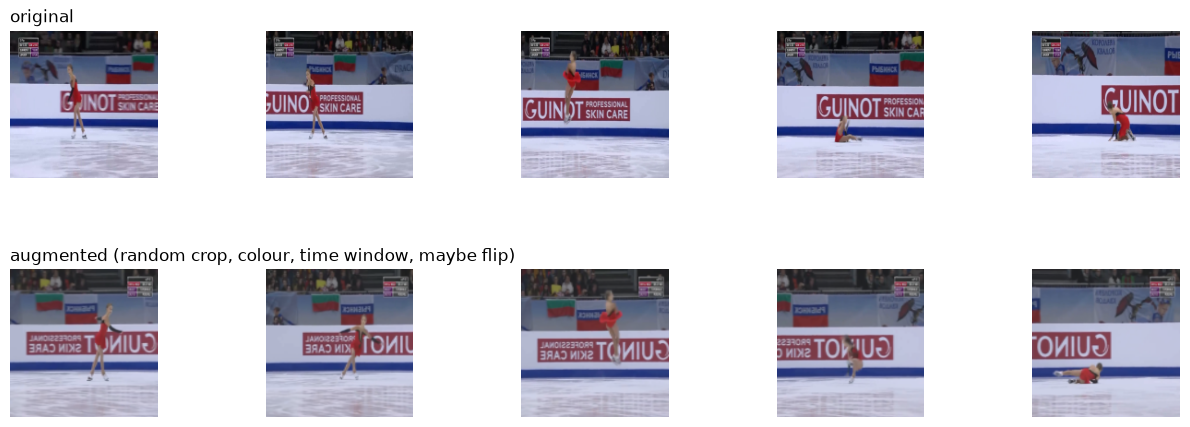

In [4]:
lab = pd.read_csv(DATA_ROOT / "labels.csv")
counts = pd.crosstab(lab.label_name, lab.split).reindex(T.CLASS_NAMES)[["train", "val", "test"]]
display(counts)

ds = T.ClipDataset(str(DATA_ROOT), "train", BASE)
x, y = ds[0]
print("sample:", tuple(x.shape), x.dtype, "label", y, T.CLASS_NAMES[y])
assert tuple(x.shape) == (3, 16, 160, 160) and x.dtype == torch.float32, "tensor does not match the data contract"
print(f"normalised values: mean {x.mean():.2f}, std {x.std():.2f} (should be roughly 0 and 1 after the model-specific normalisation)")

aug_cfg = T.apply_overrides(BASE, {"augmentation": "basic_flip"}, "viz")
aug_ds = T.ClipDataset(str(DATA_ROOT), "train", aug_cfg)
stats = T.MODEL_STATS[MODEL]
mean = torch.tensor(stats["mean"]).view(3, 1, 1, 1); std = torch.tensor(stats["std"]).view(3, 1, 1, 1)
def to_img(t, f):
    return (t * std + mean).clamp(0, 1)[:, f].permute(1, 2, 0).numpy()
xa, _ = aug_ds[0]
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for j, f in enumerate(np.linspace(0, 15, 5).astype(int)):
    ax[0, j].imshow(to_img(x, f)); ax[0, j].axis("off"); ax[1, j].imshow(to_img(xa, f)); ax[1, j].axis("off")
ax[0, 0].set_title("original", loc="left"); ax[1, 0].set_title("augmented (random crop, colour, time window, maybe flip)", loc="left")
plt.tight_layout(); plt.show()

In [5]:
# ---- forward-pass check: does the model accept our clips and return 11 raw logits (not probabilities)?
net, head = T.build_model(BASE)
T.apply_finetune_mode(net, head, BASE)
total_p, train_p = T.count_params(net)
net.eval()
with torch.no_grad():
    out = net(x.unsqueeze(0))
print(f"{MODEL}: input (1,3,16,160,160) -> output {tuple(out.shape)} | params {total_p/1e6:.1f}M, trainable in 'frozen' mode {train_p/1e6:.3f}M")
assert tuple(out.shape) == (1, 11), "model output is not (1, 11): the classifier head was not replaced correctly"
if bool((out >= 0).all()) and abs(float(out.sum()) - 1.0) < 1e-3:
    raise AssertionError("output looks like probabilities (softmax still inside the model): logits are required")
print("raw logits:", np.round(out[0].numpy(), 2))
del net, head

/home/kenzie/miniconda3/envs/deep_learning/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


x3d_s: input (1,3,16,160,160) -> output (1, 11) | params 3.0M, trainable in 'frozen' mode 0.023M
raw logits: [ 0.15  0.08  0.33  0.07  0.29 -0.12  0.02 -0.03 -0.08  0.15 -0.16]


## 2. Batch size and speed

The GPU has limited memory. `probe_batch_size` finds the largest batch that fits for **full** fine-tuning (the worst case). Use that as `BATCH_SIZE` and raise `ACCUM` so that `BATCH_SIZE * ACCUM` stays around 16. The speed test trains one epoch on 10% of the data so you can *measure* how long the real runs will take instead of guessing. The estimate below is rough (unfrozen layers are slower than frozen ones, hence the factor).

In [6]:
best_bs = T.probe_batch_size(BASE)
print("largest batch that fits:", best_bs, "(current BATCH_SIZE =", BATCH_SIZE, ")")

speed_cfg = T.apply_overrides(BASE, {"subset_frac": 0.1, "epochs": 1}, "speedtest")
sp = T.train_run(speed_cfg, force=True)
full_epoch_s = sp["sec_per_epoch"] / 0.1
n_runs = 8 if RUN_E4 else 7
sweep_min = n_runs * SWEEP_EPOCHS * full_epoch_s * SWEEP_SUBSET * 2.0 / 60
final_min = FINAL_EPOCHS * full_epoch_s * 2.0 / 60
print(f"\none FULL epoch on frozen layers ~ {full_epoch_s:.0f}s   (measured on a 10% subset)")
print(f"rough estimate (x2 for unfrozen layers): sweep ~ {sweep_min:.0f} min for ~{n_runs} runs, final training ~ {final_min:.0f} min")

  batch  4: fits, peak 1.0 GB
  batch  8: fits, peak 1.9 GB
  batch 12: fits, peak 2.8 GB
  batch 16: fits, peak 3.7 GB
  batch 24: fits, peak 5.4 GB
  batch 32: fits, peak 7.2 GB
largest batch that fits: 32 (current BATCH_SIZE = 8 )
[speedtest] x3d_s | mode=frozen opt=adamw lr=0.001 aug=off | train 1066 val 3000 | params 3.0M (trainable 0.02M) | device=cuda amp=True
  epoch  1/1 train_loss 2.334 val_loss 1.678 acc 0.526 macroF1 0.287 jumpF1 0.079 (34s)
[speedtest] best epoch 1: val macro-F1 0.287, jump macro-F1 0.079, acc 0.526

one FULL epoch on frozen layers ~ 344s   (measured on a 10% subset)
rough estimate (x2 for unfrozen layers): sweep ~ 184 min for ~8 runs, final training ~ 230 min


## 3. Experiments

Each stage trains a few variants, **picks the best by validation macro-F1**, and carries it forward (`BEST`). Identical configurations are never trained twice, so the winner of one stage is reused in the next.

* **Baseline:** pretrained backbone frozen, only the new classifier is trained, default settings.
* **E6 transfer depth:** classifier only / + last stage / everything.
* **E1 learning rate:** 0.3x, 1x and 3x of the winner's learning rate.
* **E3 augmentation:** off / crop + colour + time window / the same + horizontal flip. The flip reverses the rotation direction of a jump, so it is tested, not assumed.
* **E4 optimizer:** AdamW vs SGD with momentum.

For every stage write down *what changed, why, and what effect it had* (brief Section 10): the tables below are the evidence.

[baseline] x3d_s | mode=frozen opt=adamw lr=0.001 aug=off | train 2663 val 3000 | params 3.0M (trainable 0.02M) | device=cuda amp=True
  epoch  1/8 train_loss 2.190 val_loss 1.503 acc 0.561 macroF1 0.364 jumpF1 0.153 (40s)
  epoch  2/8 train_loss 1.780 val_loss 1.227 acc 0.620 macroF1 0.418 jumpF1 0.208 (40s)
  epoch  3/8 train_loss 1.667 val_loss 1.087 acc 0.654 macroF1 0.450 jumpF1 0.206 (42s)
  epoch  4/8 train_loss 1.599 val_loss 1.091 acc 0.657 macroF1 0.479 jumpF1 0.266 (40s)
  epoch  5/8 train_loss 1.547 val_loss 1.081 acc 0.663 macroF1 0.475 jumpF1 0.241 (40s)
  epoch  6/8 train_loss 1.519 val_loss 1.062 acc 0.675 macroF1 0.496 jumpF1 0.280 (39s)
  epoch  7/8 train_loss 1.494 val_loss 1.057 acc 0.682 macroF1 0.502 jumpF1 0.291 (40s)
  epoch  8/8 train_loss 1.487 val_loss 1.060 acc 0.682 macroF1 0.504 jumpF1 0.296 (40s)
[baseline] best epoch 8: val macro-F1 0.504, jump macro-F1 0.296, acc 0.682


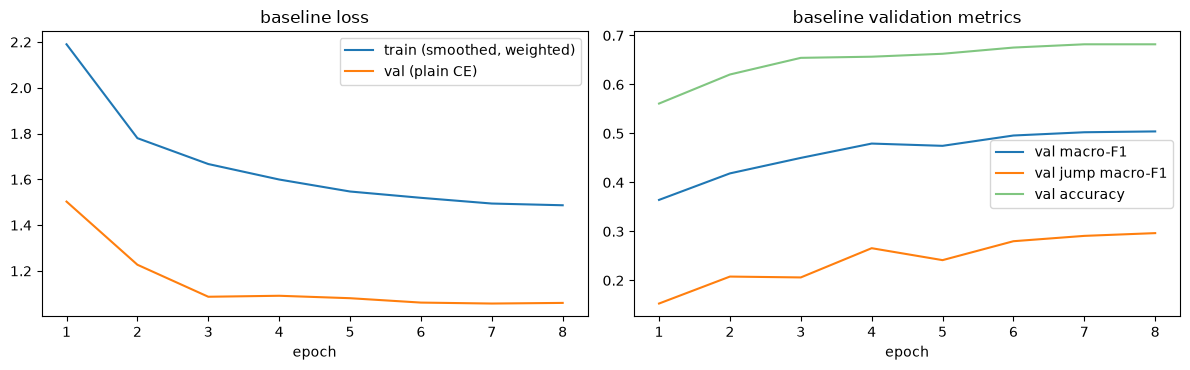

In [7]:
baseline = T.train_run(T.apply_overrides(BASE, {}, "baseline"))
T.plot_history(baseline["history"], "baseline")

In [8]:
# ---- E6: transfer-learning depth (lr differs per mode because a larger trainable part needs a smaller step)
E6 = {"frozen":  {"finetune_mode": "frozen",  "lr": 1e-3},
      "partial": {"finetune_mode": "partial", "lr": 3e-4},
      "full":    {"finetune_mode": "full",    "lr": 1e-4}}
best_e6, ov_e6, tab_e6 = T.run_stage(BASE, E6, "e6_depth")
BEST = dict(ov_e6)            # settings carried forward
display(tab_e6)

[reuse] 'e6_depth_frozen' uses identical run 'baseline' | val macro-F1 0.504
Checkpoint available: /mnt/c/Users/Kenzie/Downloads/Deep Learning/runs/x3d_s/e6_depth_frozen/best.pt
[e6_depth_partial] x3d_s | mode=partial opt=adamw lr=0.0003 aug=off | train 2663 val 3000 | params 3.0M (trainable 2.34M) | device=cuda amp=True
  epoch  1/8 train_loss 2.007 val_loss 0.915 acc 0.715 macroF1 0.486 jumpF1 0.216 (42s)
  epoch  2/8 train_loss 1.489 val_loss 0.825 acc 0.757 macroF1 0.562 jumpF1 0.309 (42s)
  epoch  3/8 train_loss 1.193 val_loss 0.704 acc 0.806 macroF1 0.655 jumpF1 0.452 (43s)
  epoch  4/8 train_loss 0.939 val_loss 0.775 acc 0.796 macroF1 0.660 jumpF1 0.463 (44s)
  epoch  5/8 train_loss 0.772 val_loss 0.680 acc 0.824 macroF1 0.693 jumpF1 0.526 (41s)
  epoch  6/8 train_loss 0.725 val_loss 0.685 acc 0.822 macroF1 0.695 jumpF1 0.523 (43s)
  epoch  7/8 train_loss 0.697 val_loss 0.675 acc 0.831 macroF1 0.697 jumpF1 0.518 (42s)
  epoch  8/8 train_loss 0.690 val_loss 0.669 acc 0.830 macroF

,variant,finetune_mode,lr,val_macro_f1,val_jump_f1,val_acc,sec_per_epoch
0,frozen,frozen,0.0010,0.504117,0.296495,0.682000,40.1
1,partial,partial,0.0003,0.698112,0.518202,0.830333,42.7
2,full,full,0.0001,0.676197,0.471567,0.815333,66.9


In [9]:
# ---- E1: learning rate around the E6 winner
lr0 = BEST["lr"]
E1 = {f"x{k}": {**BEST, "lr": lr0 * k} for k in (0.3, 1, 3)}
best_e1, ov_e1, tab_e1 = T.run_stage(BASE, E1, "e1_lr")
BEST.update(ov_e1)
display(tab_e1)

[e1_lr_x0.3] x3d_s | mode=partial opt=adamw lr=9e-05 aug=off | train 2663 val 3000 | params 3.0M (trainable 2.34M) | device=cuda amp=True
  epoch  1/8 train_loss 2.251 val_loss 1.059 acc 0.689 macroF1 0.475 jumpF1 0.217 (40s)
  epoch  2/8 train_loss 1.609 val_loss 0.844 acc 0.742 macroF1 0.531 jumpF1 0.289 (40s)
  epoch  3/8 train_loss 1.396 val_loss 0.787 acc 0.755 macroF1 0.574 jumpF1 0.326 (39s)
  epoch  4/8 train_loss 1.214 val_loss 0.782 acc 0.769 macroF1 0.602 jumpF1 0.363 (41s)
  epoch  5/8 train_loss 1.040 val_loss 0.748 acc 0.779 macroF1 0.620 jumpF1 0.390 (42s)
  epoch  6/8 train_loss 0.949 val_loss 0.786 acc 0.774 macroF1 0.617 jumpF1 0.391 (41s)
  epoch  7/8 train_loss 0.884 val_loss 0.790 acc 0.780 macroF1 0.620 jumpF1 0.393 (40s)
  epoch  8/8 train_loss 0.872 val_loss 0.781 acc 0.780 macroF1 0.620 jumpF1 0.395 (42s)
[e1_lr_x0.3] best epoch 8: val macro-F1 0.620, jump macro-F1 0.395, acc 0.780
[reuse] 'e1_lr_x1' uses identical run 'e6_depth_partial' | val macro-F1 0.698
Ch

,variant,finetune_mode,lr,val_macro_f1,val_jump_f1,val_acc,sec_per_epoch
0,x0.3,partial,0.00009,0.620217,0.395098,0.779667,40.6
1,x1,partial,0.00030,0.698112,0.518202,0.830333,42.7
2,x3,partial,0.00090,0.741177,0.586806,0.853000,39.3


In [10]:
# ---- E3: data augmentation (including the horizontal-flip ablation)
E3 = {name: {**BEST, "augmentation": name} for name in ("off", "basic", "basic_flip")}
best_e3, ov_e3, tab_e3 = T.run_stage(BASE, E3, "e3_aug")
BEST.update(ov_e3)
display(tab_e3)

[reuse] 'e3_aug_off' uses identical run 'e1_lr_x3' | val macro-F1 0.741
Checkpoint available: /mnt/c/Users/Kenzie/Downloads/Deep Learning/runs/x3d_s/e3_aug_off/best.pt
[e3_aug_basic] x3d_s | mode=partial opt=adamw lr=0.0009 aug=basic | train 2663 val 3000 | params 3.0M (trainable 2.34M) | device=cuda amp=True
  epoch  1/8 train_loss 1.919 val_loss 0.881 acc 0.706 macroF1 0.473 jumpF1 0.247 (45s)
  epoch  2/8 train_loss 1.576 val_loss 0.875 acc 0.759 macroF1 0.545 jumpF1 0.262 (45s)
  epoch  3/8 train_loss 1.390 val_loss 0.644 acc 0.812 macroF1 0.651 jumpF1 0.435 (44s)
  epoch  4/8 train_loss 1.228 val_loss 0.643 acc 0.816 macroF1 0.687 jumpF1 0.523 (45s)
  epoch  5/8 train_loss 1.069 val_loss 0.604 acc 0.847 macroF1 0.720 jumpF1 0.558 (43s)
  epoch  6/8 train_loss 0.963 val_loss 0.534 acc 0.872 macroF1 0.770 jumpF1 0.632 (44s)
  epoch  7/8 train_loss 0.871 val_loss 0.519 acc 0.872 macroF1 0.771 jumpF1 0.637 (44s)
  epoch  8/8 train_loss 0.833 val_loss 0.518 acc 0.874 macroF1 0.775 jump

,variant,finetune_mode,lr,augmentation,val_macro_f1,val_jump_f1,val_acc,sec_per_epoch
0,off,partial,0.0009,off,0.741177,0.586806,0.853000,39.3
1,basic,partial,0.0009,basic,0.775118,0.642921,0.874333,44.4
2,basic_flip,partial,0.0009,basic_flip,0.762645,0.625531,0.868333,45.0


In [11]:
# ---- E4: optimizer (SGD gets a 10x larger lr, the usual ratio between SGD and Adam-type optimizers)
if RUN_E4:
    E4 = {"adamw": {**BEST, "optimizer": "adamw"}, "sgd": {**BEST, "optimizer": "sgd", "lr": BEST["lr"] * 10}}
    best_e4, ov_e4, tab_e4 = T.run_stage(BASE, E4, "e4_opt")
    BEST.update(ov_e4)
    display(tab_e4)
else:
    print("RUN_E4 is False: skipped (optional for this model). Carried-forward optimizer:", BEST.get("optimizer", "adamw"))
print("\nCarried-forward settings:", BEST)

[reuse] 'e4_opt_adamw' uses identical run 'e3_aug_basic' | val macro-F1 0.775
Checkpoint available: /mnt/c/Users/Kenzie/Downloads/Deep Learning/runs/x3d_s/e4_opt_adamw/best.pt
[e4_opt_sgd] x3d_s | mode=partial opt=sgd lr=0.009 aug=basic | train 2663 val 3000 | params 3.0M (trainable 2.34M) | device=cuda amp=True
  epoch  1/8 train_loss 2.028 val_loss 0.986 acc 0.664 macroF1 0.449 jumpF1 0.211 (47s)
  epoch  2/8 train_loss 1.601 val_loss 0.800 acc 0.757 macroF1 0.554 jumpF1 0.308 (47s)
  epoch  3/8 train_loss 1.430 val_loss 0.781 acc 0.777 macroF1 0.605 jumpF1 0.387 (45s)
  epoch  4/8 train_loss 1.314 val_loss 0.725 acc 0.786 macroF1 0.641 jumpF1 0.424 (49s)
  epoch  5/8 train_loss 1.180 val_loss 0.659 acc 0.826 macroF1 0.698 jumpF1 0.524 (47s)
  epoch  6/8 train_loss 1.075 val_loss 0.607 acc 0.848 macroF1 0.731 jumpF1 0.576 (47s)
  epoch  7/8 train_loss 0.987 val_loss 0.569 acc 0.856 macroF1 0.742 jumpF1 0.591 (46s)
  epoch  8/8 train_loss 0.948 val_loss 0.563 acc 0.856 macroF1 0.743 j

,variant,finetune_mode,lr,augmentation,optimizer,val_macro_f1,val_jump_f1,val_acc,sec_per_epoch
0,adamw,partial,0.0009,basic,adamw,0.775118,0.642921,0.874333,44.4
1,sgd,partial,0.0090,basic,sgd,0.743089,0.596741,0.856333,46.8



Carried-forward settings: {'finetune_mode': 'partial', 'lr': 0.0009, 'augmentation': 'basic', 'optimizer': 'adamw'}


,run,mode,opt,lr,aug,subset,epochs_cfg,best_epoch,val_macro_f1,val_jump_f1,val_acc,sec/epoch,trainable_M
7,e4_opt_adamw,partial,adamw,0.00090,basic,0.25,8,8,0.7751,0.6429,0.8743,44.4,2.34
4,e3_aug_basic,partial,adamw,0.00090,basic,0.25,8,8,0.7751,0.6429,0.8743,44.4,2.34
5,e3_aug_basic_flip,partial,adamw,0.00090,basic_flip,0.25,8,8,0.7626,0.6255,0.8683,45.0,2.34
8,e4_opt_sgd,partial,sgd,0.00900,basic,0.25,8,8,0.7431,0.5967,0.8563,46.8,2.34
6,e3_aug_off,partial,adamw,0.00090,off,0.25,8,5,0.7412,0.5868,0.8530,39.3,2.34
3,e1_lr_x3,partial,adamw,0.00090,off,0.25,8,5,0.7412,0.5868,0.8530,39.3,2.34
2,e1_lr_x1,partial,adamw,0.00030,off,0.25,8,8,0.6981,0.5182,0.8303,42.7,2.34
11,e6_depth_partial,partial,adamw,0.00030,off,0.25,8,8,0.6981,0.5182,0.8303,42.7,2.34
10,e6_depth_full,full,adamw,0.00010,off,0.25,8,5,0.6762,0.4716,0.8153,66.9,3.00
1,e1_lr_x0.3,partial,adamw,0.00009,off,0.25,8,8,0.6202,0.3951,0.7797,40.6,2.34


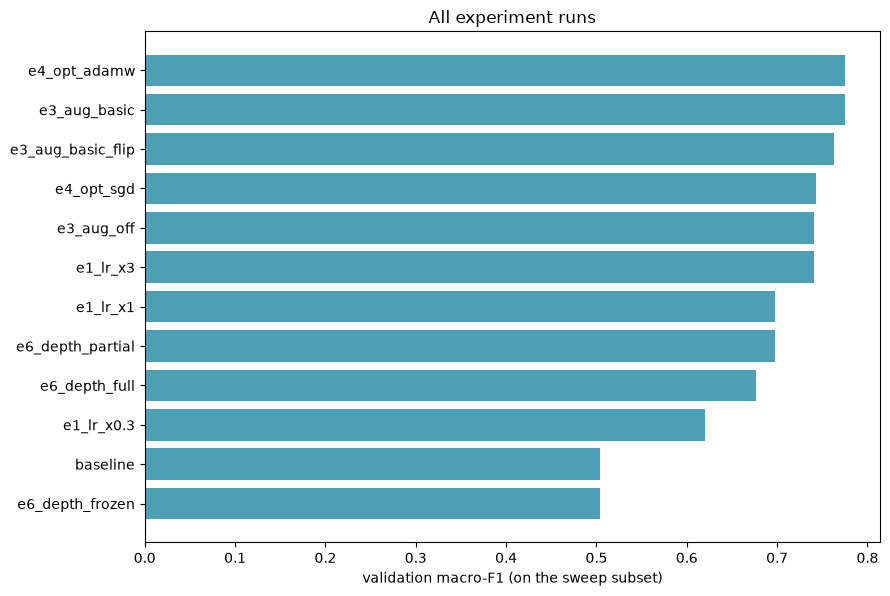

In [12]:
runs_df = T.summarize_runs(RUNS_DIR)
runs_df = runs_df[runs_df.run != "speedtest"].sort_values("val_macro_f1", ascending=False)
runs_df.to_csv(RUNS_DIR / "sweep_summary.csv", index=False)
display(runs_df)

fig, ax = plt.subplots(figsize=(9, 0.38 * len(runs_df) + 1.5))
ax.barh(runs_df.run[::-1], runs_df.val_macro_f1[::-1], color="#4C9FB5")
ax.set_xlabel("validation macro-F1 (on the sweep subset)"); ax.set_title("All experiment runs")
plt.tight_layout(); plt.show()

## 4. Final training

The winning configuration is retrained from scratch on the **full** capped train split with more epochs. Early stopping watches validation macro-F1 and the best epoch is kept.

[final] x3d_s | mode=partial opt=adamw lr=0.0009 aug=basic | train 10650 val 3000 | params 3.0M (trainable 2.34M) | device=cuda amp=True
  epoch  1/20 train_loss 1.657 val_loss 0.728 acc 0.788 macroF1 0.599 jumpF1 0.334 (119s)
  epoch  2/20 train_loss 1.260 val_loss 0.513 acc 0.874 macroF1 0.779 jumpF1 0.655 (119s)
  epoch  3/20 train_loss 1.118 val_loss 0.416 acc 0.897 macroF1 0.801 jumpF1 0.694 (121s)
  epoch  4/20 train_loss 1.052 val_loss 0.413 acc 0.906 macroF1 0.819 jumpF1 0.716 (124s)
  epoch  5/20 train_loss 0.995 val_loss 0.383 acc 0.907 macroF1 0.828 jumpF1 0.727 (123s)
  epoch  6/20 train_loss 0.959 val_loss 0.392 acc 0.914 macroF1 0.844 jumpF1 0.772 (128s)
  epoch  7/20 train_loss 0.916 val_loss 0.421 acc 0.907 macroF1 0.839 jumpF1 0.773 (127s)
  epoch  8/20 train_loss 0.887 val_loss 0.461 acc 0.899 macroF1 0.830 jumpF1 0.763 (129s)
  epoch  9/20 train_loss 0.864 val_loss 0.357 acc 0.928 macroF1 0.869 jumpF1 0.796 (128s)
  epoch 10/20 train_loss 0.837 val_loss 0.329 acc 0.9

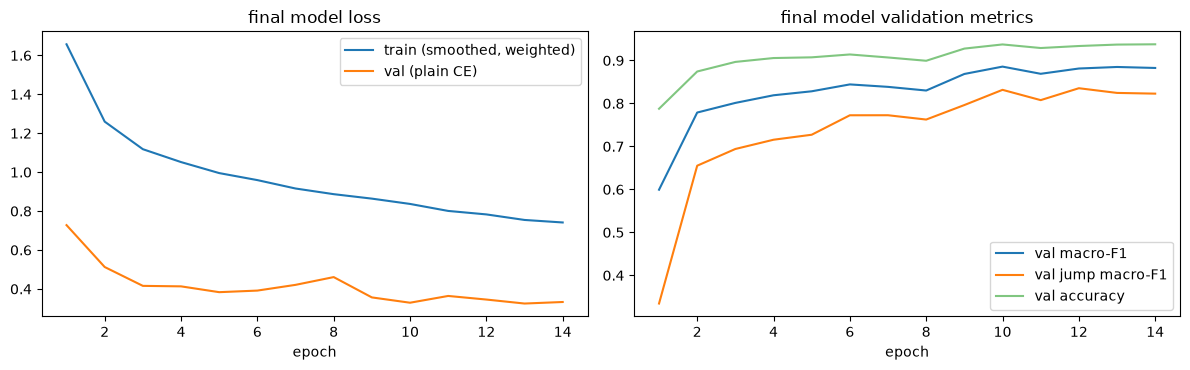

train time 29.6 min | 126s/epoch | peak VRAM 0.443361792


In [13]:
final_cfg = T.apply_overrides(BASE, {**BEST, "subset_frac": 1.0, "epochs": FINAL_EPOCHS}, "final")
final = T.train_run(final_cfg)
FINAL_CKPT = RUNS_DIR / "final" / "best.pt"
T.plot_history(final["history"], "final model")
print(f"train time {final['train_seconds']/60:.1f} min | {final['sec_per_epoch']:.0f}s/epoch | peak VRAM {final['peak_vram_gb']}")

## 5. Validation report

Read this as an analyst, not as a scoreboard. Which classes are weak? Are the errors the physically plausible ones (Flip vs Lutz share the take-off edge, which is barely visible)? Is there a gap between train and validation loss (overfitting) or are both still falling (underfitting)? Write the answers in your own words in the report.

VAL  accuracy 0.937 | macro-F1 0.886 | jump macro-F1 0.832   <- headline: jump macro-F1


,class,val_F1,val_clips
0,Toeloop,0.891,240
1,Salchow,0.802,92
2,Flip,0.732,138
3,Loop,0.874,95
4,Lutz,0.757,144
5,Axel,0.934,193
6,CamelSpin,0.987,373
7,SitSpin,0.977,394
8,UprightSpin,0.954,320
9,NoBasic,0.839,96


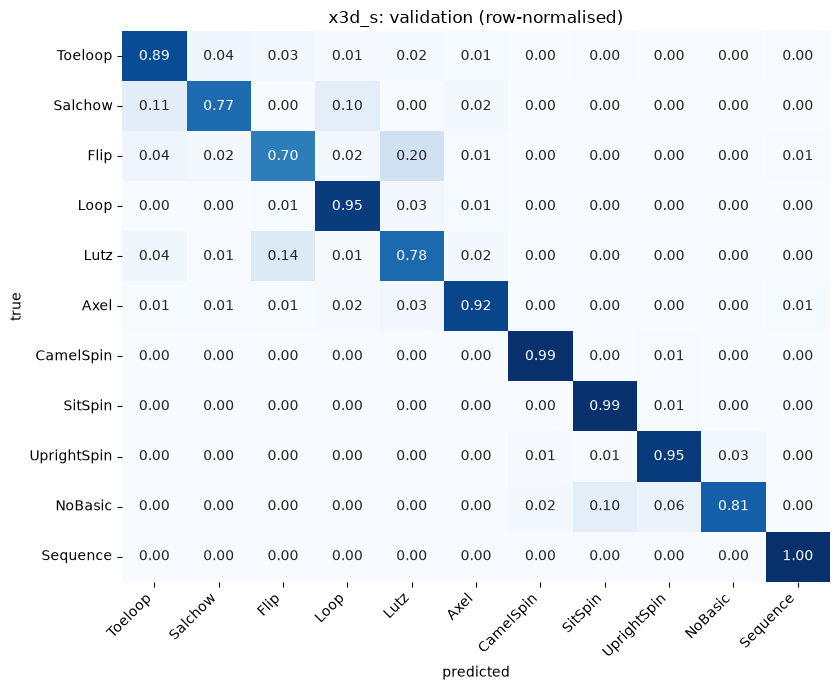

most frequent confusions (true, predicted, count):
          Flip -> Lutz         27
          Lutz -> Flip         20
       Salchow -> Toeloop      10
   UprightSpin -> NoBasic      10
       NoBasic -> SitSpin      10
       Toeloop -> Salchow      9


In [14]:
val = T.evaluate_split(final_cfg, FINAL_CKPT, "val")
m = val["metrics"]
print(f"VAL  accuracy {m['acc']:.3f} | macro-F1 {m['macro_f1']:.3f} | jump macro-F1 {m['jump_macro_f1']:.3f}   <- headline: jump macro-F1")
display(pd.DataFrame({"class": T.CLASS_NAMES, "val_F1": np.round(m["per_class_f1"], 3),
                      "val_clips": val["confusion"].sum(axis=1)}))
T.plot_confusion(val["confusion"], f"{MODEL}: validation (row-normalised)")
print("most frequent confusions (true, predicted, count):")
for t_, p_, n_ in T.top_confusions(val["confusion"]):
    print(f"  {t_:>12} -> {p_:<12} {n_}")

## 6. Calibration, latency and export for the web app

* **Temperature scaling** (fitted on validation only) makes the probabilities honest: a 90% prediction should be right about 90% of the time.
* **Ambiguity margin:** if (top-1 minus top-2 probability) is below this value the app shows two classes ("Flip or Lutz?"). It is chosen on validation as the smallest margin whose confident predictions reach 95% accuracy.
* **CPU latency** is measured with 2 threads (the size of a free Hugging Face CPU Space). Treat it as the deployment cost of this model.
* **ONNX export** and a parity check against PyTorch. `deployment_meta.json` is what Person 3 reads; nothing is hard-coded in the app.

In [15]:
%pip install onnxruntime

Note: you may need to restart the kernel to use updated packages.


In [16]:
temperature = T.fit_temperature(val["logits"], val["labels"])
val_probs = T.softmax_np(val["logits"], temperature)
margin, margin_table = T.choose_ambiguity_margin(val_probs, val["labels"], target_acc=0.95)
print(f"temperature {temperature:.3f} | ambiguity margin {margin:.2f}")
display(margin_table.iloc[::2].round(3))

lat = T.benchmark_cpu_latency(final_cfg)
print(f"CPU latency per clip ({lat['threads']} threads): median {lat['cpu_ms_median']:.0f} ms, p90 {lat['cpu_ms_p90']:.0f} ms")

exp = T.export_onnx(final_cfg, FINAL_CKPT, EXPORT_DIR / "model.onnx")
print("ONNX:", exp)
assert exp.get("parity_ok") in (True, None), "ONNX output differs from PyTorch: do NOT hand this model to Person 3"
shutil.copy(FINAL_CKPT, EXPORT_DIR / "weights.pt")

meta = T.write_deployment_meta(EXPORT_DIR / "deployment_meta.json", EXPORT_NAME, final_cfg, temperature, margin,
                               m["macro_f1"], m["jump_macro_f1"],
                               extra={**lat, **exp, "params_total": final["params_total"], "train_seconds": final["train_seconds"],
                                      "dev_mode": DEV_MODE})

PRED_DIR.mkdir(parents=True, exist_ok=True)
np.savez(PRED_DIR / f"{EXPORT_NAME}_val.npz", probs=T.softmax_np(val["logits"]), probs_calibrated=val_probs,
         logits=val["logits"], labels=val["labels"], clip_ids=val["clip_ids"], temperature=np.array(temperature))
print("wrote", EXPORT_DIR.relative_to(REPO_ROOT), "and", (PRED_DIR / f"{EXPORT_NAME}_val.npz").relative_to(REPO_ROOT))

temperature 0.663 | ambiguity margin 0.40


,margin,coverage,acc_confident
0,0.0,1.000,0.937
2,0.1,0.992,0.941
4,0.2,0.985,0.945
6,0.3,0.977,0.948
8,0.4,0.965,0.951
10,0.5,0.953,0.956
12,0.6,0.941,0.960
14,0.7,0.926,0.964
16,0.8,0.903,0.971
18,0.9,0.858,0.979


CPU latency per clip (2 threads): median 145 ms, p90 146 ms
ONNX: {'onnx_path': '/mnt/c/Users/Kenzie/Downloads/Deep Learning/export/x3d/model.onnx', 'onnx_mb': 12.0, 'opset': 17, 'export_strategy': 'classic exporter, dynamic batch', 'dynamic_batch': True, 'swish_replaced': 26, 'max_abs_diff_vs_pytorch': 5.617737770080566e-06, 'parity_ok': True}
wrote export/x3d and predictions/x3d_val.npz


## 7. Test evaluation (once)

Set `EVALUATE_TEST = True` **only after** the final model is fixed. Looking at test results and then changing the model turns the test split into a second validation split, and the reported numbers stop being honest. If you must change something after seeing the test score, say so in the report.

/home/kenzie/miniconda3/envs/deep_learning/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


TEST accuracy 0.929 | macro-F1 0.870 | jump macro-F1 0.817


,class,test_F1,test_clips
0,Toeloop,0.897,240
1,Salchow,0.787,93
2,Flip,0.720,138
3,Loop,0.800,93
4,Lutz,0.776,144
5,Axel,0.926,193
6,CamelSpin,0.982,373
7,SitSpin,0.970,395
8,UprightSpin,0.946,321
9,NoBasic,0.771,96


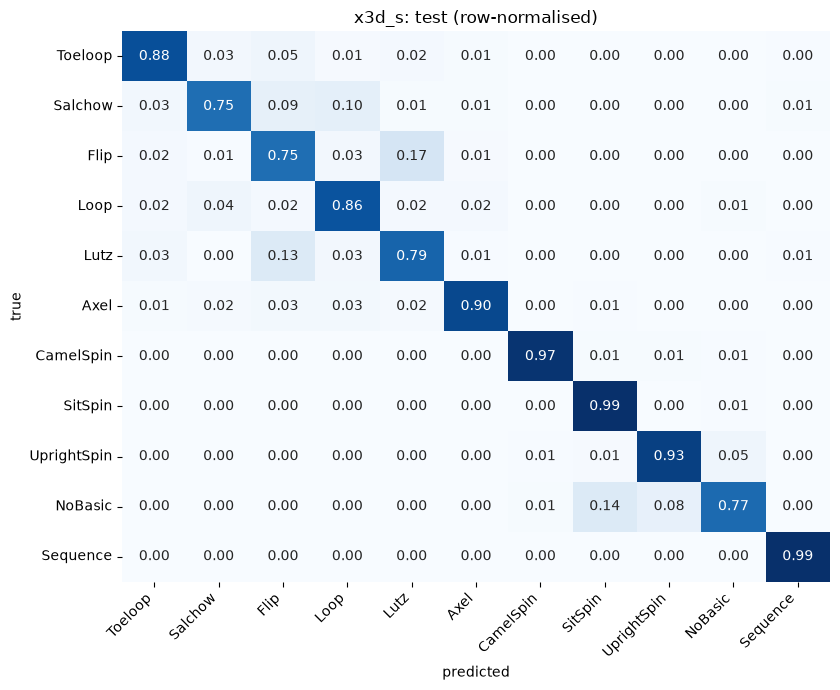

In [4]:
if EVALUATE_TEST:
    test = T.evaluate_split(final_cfg, FINAL_CKPT, "test")
    mt = test["metrics"]
    print(f"TEST accuracy {mt['acc']:.3f} | macro-F1 {mt['macro_f1']:.3f} | jump macro-F1 {mt['jump_macro_f1']:.3f}")
    display(pd.DataFrame({"class": T.CLASS_NAMES, "test_F1": np.round(mt["per_class_f1"], 3), "test_clips": test["confusion"].sum(axis=1)}))
    T.plot_confusion(test["confusion"], f"{MODEL}: test (row-normalised)")
    np.savez(PRED_DIR / f"{EXPORT_NAME}_test.npz", probs=T.softmax_np(test["logits"]),
             probs_calibrated=T.softmax_np(test["logits"], temperature), logits=test["logits"], labels=test["labels"],
             clip_ids=test["clip_ids"], temperature=np.array(temperature))
    (RUNS_DIR / "test_metrics.json").write_text(json.dumps(mt, indent=2))
else:
    print("EVALUATE_TEST is False: test split not touched.")

## 8. Facts for the report

Everything below was measured by this notebook, so it can go into the report. Copy the *numbers*, write the *interpretation* yourself.

In [18]:
facts = {"model": MODEL, "dev_mode": DEV_MODE, "best_settings": BEST, "final_epochs_run": len(final["history"]),
         "best_epoch": final["best_epoch"], "val_macro_f1": m["macro_f1"], "val_jump_macro_f1": m["jump_macro_f1"],
         "val_acc": m["acc"], "params_total_M": round(final["params_total"] / 1e6, 2),
         "train_minutes": round(final["train_seconds"] / 60, 1), "sec_per_epoch": round(final["sec_per_epoch"], 1),
         "peak_vram_gb": final["peak_vram_gb"], "cpu_ms_median_2threads": round(lat["cpu_ms_median"], 0),
         "onnx_mb": exp["onnx_mb"], "temperature": temperature, "ambiguity_margin": margin}
(RUNS_DIR / "report_facts.json").write_text(json.dumps(facts, indent=2, default=str))
display(pd.Series(facts).to_frame("value"))
if DEV_MODE:
    print("\nDEV_MODE results are from a 143-clip pipeline check: they are NOT results. Set DEV_MODE = False and run the real experiments.")

,value
model,x3d_s
dev_mode,False
best_settings,"{'finetune_mode': 'partial', 'lr': 0.0009, 'au..."
final_epochs_run,14
best_epoch,10
val_macro_f1,0.885729
val_jump_macro_f1,0.831688
val_acc,0.937333
params_total_M,3.0
train_minutes,29.6


### Still on your list
1. Run the whole notebook once with `DEV_MODE = True`, fix any install problem, then run it for real.
2. In the report: for each experiment state *what changed, why, and the effect* (use the stage tables); discuss over/underfitting from the loss curves; discuss the confusion matrix; state the trade-off between accuracy and CPU latency.
3. Tell Person 3 when `export/x3d/` is final; tell the team which model you recommend to deploy and why.
4. Log every AI use in the AI usage table, including mistakes you found.